# Lab 04 - Fine-Tuning an LLM using LoRA/QLoRA

In [ ]:
!pip install -q -U transformers datasets peft trl accelerate bitsandbytes

import torch, transformers, datasets, peft, trl, accelerate, bitsandbytes

print("transformers :", transformers.__version__)
print("datasets     :", datasets.__version__)
print("peft         :", peft.__version__)
print("trl          :", trl.__version__)
print("accelerate   :", accelerate.__version__)
print("bitsandbytes :", bitsandbytes.__version__)

transformers : 5.24.1
datasets     : 5.2.0
peft         : 0.22.0
trl          : 1.19.0
accelerate   : 1.16.0
bitsandbytes : 0.50.2


In [ ]:
import os, subprocess, psutil

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    free, total = torch.cuda.mem_get_info()
    print("GPU name        :", props.name)
    print(f"Total GPU memory: {props.total_memory / 1024**3:.1f} GB")
    print(f"Free GPU memory : {free / 1024**3:.1f} GB")
    print()
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
else:
    print("No GPU is connected (Colab free GPU limit reached). Everything will run on the CPU.")
    print("CPU cores       :", os.cpu_count())
    print(f"System memory   : {psutil.virtual_memory().total / 1024**3:.1f} GB")

GPU available: False
No GPU is connected (Colab free GPU limit reached). Everything will run on the CPU.
CPU cores       : 2
System memory   : 12.7 GB


## Task 2 - GPU

**GPU available:** No GPU was available. The free Colab GPU limit had been reached, so this session ran on the CPU (2 CPU cores and 12.7 GB of system memory).

**Why a GPU is useful for LLM fine-tuning:** Fine-tuning needs millions of small maths calculations (matrix multiplications) at the same time. A CPU does them mostly one after another, while a GPU has thousands of small cores that do them in parallel, so training is many times faster. The GPU's memory also has to hold the model, the training data and the values used for learning, so the amount of GPU memory limits how big a model can be trained. This is why LoRA and QLoRA, which save memory, are useful.

In [ ]:
import json
from datasets import Dataset

SYSTEM_PROMPT = "You are a helpful assistant."

# 40 question-and-answer pairs about the (made-up) shop "TechNest Computers", Colombo
qa_pairs = [
    ("What are your opening hours?", "TechNest Computers is open Monday to Saturday from 9:00 AM to 7:00 PM and on Sunday from 10:00 AM to 4:00 PM. We are closed on Poya days."),
    ("Where is the shop located?", "TechNest Computers is at No. 45, Galle Road, Colombo 03."),
    ("What is your phone number?", "You can call us on 011 555 0142 during opening hours."),
    ("Do you have WhatsApp?", "Yes. Message us on WhatsApp at 077 555 0199 for quick questions and order updates."),
    ("How long is the warranty on laptops?", "All new laptops sold by TechNest Computers come with a 2-year warranty."),
    ("What is the warranty on desktop computers?", "Desktop computers come with a 3-year warranty."),
    ("What is the warranty on keyboards and mice?", "Keyboards, mice and other small accessories have a 6-month warranty."),
    ("How long is the warranty on SSDs?", "SSDs come with a 3-year warranty."),
    ("What does the warranty not cover?", "The warranty does not cover physical damage, liquid damage or damage caused by unauthorised repairs."),
    ("What do I need to make a warranty claim?", "Please bring the item, the original invoice and the serial number. Without the invoice, we cannot process the claim."),
    ("What is your return policy?", "You can return an unopened item in its original packaging within 7 days of purchase for a full refund."),
    ("What if I receive a faulty item?", "If an item is faulty when you receive it, we will replace it free of charge within 14 days of purchase."),
    ("Do you charge for diagnosing a problem?", "We charge a diagnostic fee of LKR 1,500, which is waived if you go ahead with the repair."),
    ("How much does it cost to reinstall Windows?", "A Windows reinstallation costs LKR 3,500, including basic drivers."),
    ("How much is virus removal?", "Virus and malware removal costs LKR 2,500."),
    ("How much does a laptop cleaning service cost?", "A full internal laptop cleaning with new thermal paste costs LKR 4,000."),
    ("How long does a simple repair take?", "Simple repairs usually take 2 to 3 working days."),
    ("How long do motherboard repairs take?", "Motherboard repairs can take up to 10 working days."),
    ("Do you recover data from damaged drives?", "Yes. Data recovery starts from LKR 8,000, depending on the damage. We only charge if the data is recovered."),
    ("What payment methods do you accept?", "We accept cash, Visa and Mastercard cards, and bank transfers."),
    ("Do you offer instalment plans?", "Yes. For purchases above LKR 100,000, we offer 0% interest instalments for up to 6 months on selected bank cards."),
    ("Do you offer a student discount?", "Yes. Students with a valid student ID get 5% off laptops and 10% off accessories."),
    ("Do you deliver?", "We deliver free within Colombo for orders above LKR 50,000. Islandwide courier delivery takes 2 to 3 working days and costs LKR 650."),
    ("Can I pick up my order in the shop?", "Yes. Orders for in-store pickup are usually ready within 2 hours."),
    ("Can I cancel an order?", "You can cancel an order free of charge within 24 hours, as long as it has not been dispatched."),
    ("Which laptop brands do you sell?", "We sell Dell, HP, Lenovo and ASUS laptops."),
    ("How much do your student laptops cost?", "Our student laptop range starts at LKR 165,000."),
    ("Do you sell refurbished laptops?", "Yes. Our refurbished laptops are tested by our technicians and come with a 1-year warranty."),
    ("Can I trade in my old laptop?", "Yes. You can trade in a working old laptop for credit of up to 20% of the price of a new one."),
    ("Do you build custom PCs?", "Yes. We build custom PCs, and assembly is free if you buy all the parts from us."),
    ("Do you have a loyalty programme?", "Yes, it is called NestPoints. You earn 1 point for every LKR 100 spent, and 100 points give you LKR 500 off."),
    ("Do you sell gift vouchers?", "Yes. Gift vouchers are available in LKR 5,000, LKR 10,000 and LKR 25,000 amounts and are valid for 12 months."),
    ("Do you upgrade RAM?", "Yes. RAM upgrades have no labour charge if you buy the RAM from us."),
    ("How can I check the status of my repair?", "Send your repair ticket number to our WhatsApp number 077 555 0199 and we will tell you the status."),
    ("Will you back up my data before a repair?", "Yes, on request. Data backup costs LKR 1,000 per 100 GB. We are not responsible for lost data if you do not ask for a backup."),
    ("What is the warranty on laptop batteries?", "Laptop batteries have a 1-year warranty."),
    ("Do you repair laptop screens?", "Yes. The price of a screen replacement depends on the model, and we will give you a quote after checking your laptop."),
    ("Are you open on public holidays?", "We are closed on Poya days. On other public holidays we are open from 10:00 AM to 4:00 PM."),
    ("What is TechNest Computers?", "TechNest Computers is a computer shop in Colombo that sells laptops, desktops and accessories, and offers repair and upgrade services."),
    ("Do you sell monitors?", "Yes. Monitors from 19 to 32 inches come with a 2-year warranty."),
]

print("Number of question-and-answer pairs:", len(qa_pairs))
assert len(qa_pairs) >= 30, "The lab needs at least 30 pairs"

# Convert to the chat format that the trainer expects
train_dataset = Dataset.from_list([
    {"messages": [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": q},
        {"role": "assistant", "content": a},
    ]}
    for q, a in qa_pairs
])

# Save a copy of the dataset so it can go into GitHub
with open("technest_qa_dataset.json", "w") as f:
    json.dump([{"question": q, "answer": a} for q, a in qa_pairs], f, indent=2)

print(train_dataset)
print()
for i in range(3):
    print("Q:", qa_pairs[i][0])
    print("A:", qa_pairs[i][1])
    print()

Number of question-and-answer pairs: 40
Dataset({
    features: ['messages'],
    num_rows: 40
})

Q: What are your opening hours?
A: TechNest Computers is open Monday to Saturday from 9:00 AM to 7:00 PM and on Sunday from 10:00 AM to 4:00 PM. We are closed on Poya days.

Q: Where is the shop located?
A: TechNest Computers is at No. 45, Galle Road, Colombo 03.

Q: What is your phone number?
A: You can call us on 011 555 0142 during opening hours.



In [ ]:
# 10 test questions. NONE of them is word-for-word in the training data.
test_set = [
    # Type A: the SAME facts as in training, but asked in a different way
    {"type": "reworded", "question": "What time do you close on Saturdays?",
     "expected": "7:00 PM"},
    {"type": "reworded", "question": "My laptop broke after 18 months. Is it still under warranty?",
     "expected": "Yes, laptops have a 2-year warranty"},
    {"type": "reworded", "question": "I am a university student. Can I get a cheaper price?",
     "expected": "5% off laptops and 10% off accessories with a student ID"},
    {"type": "reworded", "question": "How much will you charge to get rid of a virus on my PC?",
     "expected": "LKR 2,500"},
    {"type": "reworded", "question": "I bought a sealed keyboard 5 days ago and changed my mind. Can I return it?",
     "expected": "Yes, unopened items can be returned within 7 days"},
    {"type": "reworded", "question": "Can I pay for an expensive laptop in monthly payments?",
     "expected": "Yes, 0% instalments up to 6 months for purchases above LKR 100,000 on selected cards"},
    # Type B: facts that are NOT in the training data (the ideal answer is "I don't know")
    {"type": "not in training", "question": "Does TechNest Computers have a branch in Kandy?",
     "expected": "Unknown - ideally the model says it does not know"},
    {"type": "not in training", "question": "Who is the owner of TechNest Computers?",
     "expected": "Unknown - ideally the model says it does not know"},
    # Type C: general knowledge (to check that the model did not forget what it knew)
    {"type": "general", "question": "What is the capital of Japan?",
     "expected": "Tokyo"},
    {"type": "general", "question": "What does RAM stand for?",
     "expected": "Random Access Memory"},
]

print("Number of test questions:", len(test_set))
print()
for t in test_set:
    print(f"[{t['type']}] {t['question']}")
    print(f"    Expected: {t['expected']}")

Number of test questions: 10

[reworded] What time do you close on Saturdays?
    Expected: 7:00 PM
[reworded] My laptop broke after 18 months. Is it still under warranty?
    Expected: Yes, laptops have a 2-year warranty
[reworded] I am a university student. Can I get a cheaper price?
    Expected: 5% off laptops and 10% off accessories with a student ID
[reworded] How much will you charge to get rid of a virus on my PC?
    Expected: LKR 2,500
[reworded] I bought a sealed keyboard 5 days ago and changed my mind. Can I return it?
    Expected: Yes, unopened items can be returned within 7 days
[reworded] Can I pay for an expensive laptop in monthly payments?
    Expected: Yes, 0% instalments up to 6 months for purchases above LKR 100,000 on selected cards
[not in training] Does TechNest Computers have a branch in Kandy?
    Expected: Unknown - ideally the model says it does not know
[not in training] Who is the owner of TechNest Computers?
    Expected: Unknown - ideally the model says

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "HuggingFaceTB/SmolLM2-360M-Instruct"
device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float16 if device == "cuda" else torch.float32

tokenizer = AutoTokenizer.from_pretrained(model_name)
base_model = AutoModelForCausalLM.from_pretrained(model_name, dtype=dtype).to(device)

num_params = sum(p.numel() for p in base_model.parameters())
print("Model            :", model_name)
print(f"Parameters       : {num_params:,}")
print(f"Memory used      : {base_model.get_memory_footprint() / 1024**3:.2f} GB")
print("Running on       :", base_model.device)

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.76k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  724MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Model            : HuggingFaceTB/SmolLM2-360M-Instruct
Parameters       : 361,821,120
Memory used      : 1.35 GB
Running on       : cpu


In [ ]:
import time

def ask(m, question, max_new_tokens=80):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": question},
    ]
    text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(m.device)
    with torch.no_grad():
        out = m.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                         pad_token_id=tokenizer.eos_token_id)   # no randomness = fair comparison
    answer_ids = out[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(answer_ids, skip_special_tokens=True).strip()

base_answers = {}
start = time.time()
for t in test_set:
    ans = ask(base_model, t["question"])
    base_answers[t["question"]] = ans
    print(f"[{t['type']}] QUESTION: {t['question']}")
    print(f"EXPECTED: {t['expected']}")
    print(f"ORIGINAL MODEL: {ans}")
    print("-" * 80)

print(f"Done in {time.time() - start:.0f} seconds")

[reworded] QUESTION: What time do you close on Saturdays?
EXPECTED: 7:00 PM
ORIGINAL MODEL: I'm sorry for any confusion, but as an AI, I don't have real-time access to current schedules or times. I recommend checking the local business hours or website for the most accurate information.
--------------------------------------------------------------------------------
[reworded] QUESTION: My laptop broke after 18 months. Is it still under warranty?
EXPECTED: Yes, laptops have a 2-year warranty
ORIGINAL MODEL: Yes, it is still under warranty. The warranty period typically ranges from 12 to 18 months, depending on the manufacturer and the specific model of your laptop.
--------------------------------------------------------------------------------
[reworded] QUESTION: I am a university student. Can I get a cheaper price?
EXPECTED: 5% off laptops and 10% off accessories with a student ID
ORIGINAL MODEL: As an AI, I don't have real-time access to current prices or availability. I can sugges

## Task 3 - Model choice

**Model chosen:** HuggingFaceTB/SmolLM2-360M-Instruct (about 360 million parameters).

**Why:** It is a small, instruction-tuned causal language model, which means it already knows how to follow instructions and answer in a chat style. It is one of the models suggested in the lab sheet and it is supported by the current Hugging Face tools (transformers, peft and trl). No GPU was available in this session (the free GPU limit was reached), so I chose the smaller of the two suggested models, because it trains and answers faster on a CPU.

In [ ]:
from peft import LoraConfig, get_peft_model

# A fresh copy of the model to fine-tune (the original answers are already saved in base_answers)
ft_base = AutoModelForCausalLM.from_pretrained(model_name, dtype=torch.float32).to(device)

lora_config = LoraConfig(
    r=16,                 # size of the small add-on layers (the "rank")
    lora_alpha=32,        # how strongly the add-ons are applied
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    bias="none",
    task_type="CAUSAL_LM",
)

peft_model = get_peft_model(ft_base, lora_config)

trainable = sum(p.numel() for p in peft_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in peft_model.parameters())
print(f"Trainable parameters : {trainable:,}")
print(f"Total parameters     : {total:,}")
print(f"Share being trained  : {100 * trainable / total:.2f}%")

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but only versions above 0.16.0 are supported. torchao support in PEFT is disabled; if you want to use a torchao-quantized model with PEFT, please upgrade torchao.
  warnings.warn(


Trainable parameters : 8,683,520
Total parameters     : 370,504,640
Share being trained  : 2.34%


## Task 5 - LoRA configuration (and why not QLoRA)

I used **LoRA** with the PEFT library. The original model is frozen and only small add-on matrices (rank r = 16, alpha = 32, dropout 0.05) are trained. They are attached to the attention layers (q, k, v, o) and the feed-forward layers (gate, up, down).

**QLoRA** (LoRA plus a 4-bit compressed base model) needs a GPU, because the 4-bit library (bitsandbytes) runs on CUDA. No GPU was available in this session, and the model is small enough to fit in normal memory, so QLoRA was not needed or possible. The lab sheet says to use QLoRA only if GPU memory is limited.

In [ ]:
from trl import SFTTrainer, SFTConfig

training_args = SFTConfig(
    output_dir="technest_lora_out",
    num_train_epochs=6,
    per_device_train_batch_size=4,
    learning_rate=3e-4,
    logging_steps=5,
    max_length=256,
    save_strategy="no",
    report_to="none",
    use_cpu=not torch.cuda.is_available(),   # train on the CPU when there is no GPU
    bf16=False,                               # these number formats need a GPU
    fp16=False,
)

trainer = SFTTrainer(
    model=peft_model,
    args=training_args,
    train_dataset=train_dataset,
    processing_class=tokenizer,
)

print("Starting training...")
start = time.time()
trainer.train()
print(f"Training finished in {(time.time() - start) / 60:.1f} minutes")

Tokenizing train dataset:   0%|          | 0/40 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/40 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/40 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/40 [00:00<?, ? examples/s]

Starting training...


Step,Training Loss
5,0.187006
10,0.222915
15,0.146417
20,0.153546
25,0.104657
30,0.132159
35,0.090998
40,0.106524
45,0.088399
50,0.087868


Training finished in 17.7 minutes


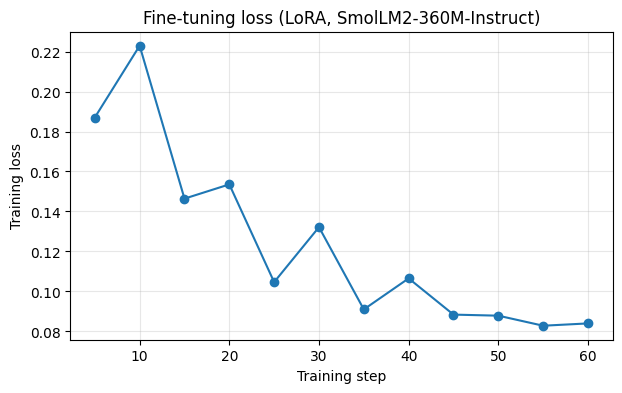

First logged loss: 0.187
Last logged loss : 0.084


In [12]:
import matplotlib.pyplot as plt

logs = [l for l in trainer.state.log_history if "loss" in l]
steps = [l["step"] for l in logs]
losses = [l["loss"] for l in logs]

plt.figure(figsize=(7, 4))
plt.plot(steps, losses, marker="o")
plt.title("Fine-tuning loss (LoRA, SmolLM2-360M-Instruct)")
plt.xlabel("Training step")
plt.ylabel("Training loss")
plt.grid(alpha=0.3)
plt.show()

print("First logged loss:", round(losses[0], 3))
print("Last logged loss :", round(losses[-1], 3))

In [13]:
import pandas as pd

peft_model.eval()

# 3 questions that WERE in the training data (to compare with the unseen ones)
picks = [qa_pairs[4], qa_pairs[13], qa_pairs[30]]
all_tests = test_set + [
    {"type": "training question", "question": q, "expected": a} for q, a in picks
]

rows = []
start = time.time()
for t in all_tests:
    q = t["question"]
    if q not in base_answers:
        base_answers[q] = ask(base_model, q)          # original model's answer
    ft = ask(peft_model, q)                           # fine-tuned model's answer
    rows.append({"Type": t["type"], "Question": q, "Expected": t["expected"],
                 "Original model": base_answers[q], "Fine-tuned model": ft})

    print(f"[{t['type']}] QUESTION: {q}")
    print(f"EXPECTED      : {t['expected']}")
    print(f"ORIGINAL MODEL: {base_answers[q][:160]}")
    print(f"FINE-TUNED    : {ft}")
    print("-" * 80)

print(f"Done in {time.time() - start:.0f} seconds")

results_df = pd.DataFrame(rows)
results_df.to_csv("comparison_results.csv", index=False)

[reworded] QUESTION: What time do you close on Saturdays?
EXPECTED      : 7:00 PM
ORIGINAL MODEL: I'm sorry for any confusion, but as an AI, I don't have real-time access to current schedules or times. I recommend checking the local business hours or website
FINE-TUNED    : TechNest Computers, Laptops and Internet Offerers, Chemistry, Biology, Physics and Mathematics Books, and Art Supplies are available for sale on Saturdays from 3:00 PM to 7:00 PM.
--------------------------------------------------------------------------------
[reworded] QUESTION: My laptop broke after 18 months. Is it still under warranty?
EXPECTED      : Yes, laptops have a 2-year warranty
ORIGINAL MODEL: Yes, it is still under warranty. The warranty period typically ranges from 12 to 18 months, depending on the manufacturer and the specific model of your laptop.
FINE-TUNED    : Yes. Your laptop is still under warranty for 24 months.
--------------------------------------------------------------------------------


In [14]:
import shutil
from peft import get_peft_model_state_dict
from safetensors.torch import save_file
from google.colab import files

adapter_dir = "technest_lora_adapter"
os.makedirs(adapter_dir, exist_ok=True)

# Save only the small LoRA weights (in half precision to keep the file small)
adapter_weights = {k: v.detach().cpu().half().contiguous()
                   for k, v in get_peft_model_state_dict(peft_model).items()}
save_file(adapter_weights, f"{adapter_dir}/adapter_model.safetensors")
peft_model.peft_config["default"].save_pretrained(adapter_dir)   # adapter_config.json
tokenizer.save_pretrained(adapter_dir)

print("Saved files:")
for f in sorted(os.listdir(adapter_dir)):
    print(f"  {f}  ({os.path.getsize(os.path.join(adapter_dir, f)) / 1024:.0f} KB)")

# Download everything we need for GitHub
files.download("comparison_results.csv")
files.download("technest_qa_dataset.json")
shutil.make_archive("technest_lora_adapter", "zip", adapter_dir)
files.download("technest_lora_adapter.zip")

Saved files:
  adapter_config.json  (1 KB)
  adapter_model.safetensors  (17017 KB)
  chat_template.jinja  (0 KB)
  tokenizer.json  (3440 KB)
  tokenizer_config.json  (0 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>